# **Flight Price Prediction**

---



*   Project level: Beginner
*   Learning Mode: Theory + Google colab practical
*   Algorithm: Multiple Linear Regression
*   Input features: Class, Duration, Days Left, Stops
*   Target variable: Flight Price
*   Primary tools: Python,Pandas,Matplotlib,Scikit-learn

In [8]:
#Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

print("Libraries imported successfully")

Libraries imported successfully


In [9]:
#Loading the Dataset
df = pd.read_csv('/content/DATASET_clean.csv')

print("Dataset loaded successfully")
print(df.head())

Dataset loaded successfully
   id   airline   flight source_city departure_time  stops   arrival_time  \
0   0  SpiceJet  SG-8709       Delhi        Evening      0          Night   
1   1  SpiceJet  SG-8157       Delhi  Early_Morning      0        Morning   
2   2   AirAsia   I5-764       Delhi  Early_Morning      0  Early_Morning   
3   3   Vistara   UK-995       Delhi        Morning      0      Afternoon   
4   4   Vistara   UK-963       Delhi        Morning      0        Morning   

  destination_city  class  duration  days_left  price  
0           Mumbai      0      2.17          1   5953  
1           Mumbai      0      2.33          1   5953  
2           Mumbai      0      2.17          1   5956  
3           Mumbai      0      2.25          1   5955  
4           Mumbai      0      2.33          1   5955  


In [10]:
#Inspect the dataset
print("First five rows:")
print(df.head())

print("\nLast five rows:")
print(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nDataset names:")
print(df.columns)

print("\nDataset info:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

First five rows:
   id   airline   flight source_city departure_time  stops   arrival_time  \
0   0  SpiceJet  SG-8709       Delhi        Evening      0          Night   
1   1  SpiceJet  SG-8157       Delhi  Early_Morning      0        Morning   
2   2   AirAsia   I5-764       Delhi  Early_Morning      0  Early_Morning   
3   3   Vistara   UK-995       Delhi        Morning      0      Afternoon   
4   4   Vistara   UK-963       Delhi        Morning      0        Morning   

  destination_city  class  duration  days_left  price  
0           Mumbai      0      2.17          1   5953  
1           Mumbai      0      2.33          1   5953  
2           Mumbai      0      2.17          1   5956  
3           Mumbai      0      2.25          1   5955  
4           Mumbai      0      2.33          1   5955  

Last five rows:
            id  airline  flight source_city departure_time  stops  \
300148  300148  Vistara  UK-822     Chennai        Morning      1   
300149  300149  Vistara  UK-8

In [11]:
# Check Data Quality

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print(df['price'].describe())

Missing values:
id                  0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

Duplicate Rows:
0
count    300153.000000
mean      20889.660523
std       22697.767366
min        1105.000000
25%        4783.000000
50%        7425.000000
75%       42521.000000
max      123071.000000
Name: price, dtype: float64


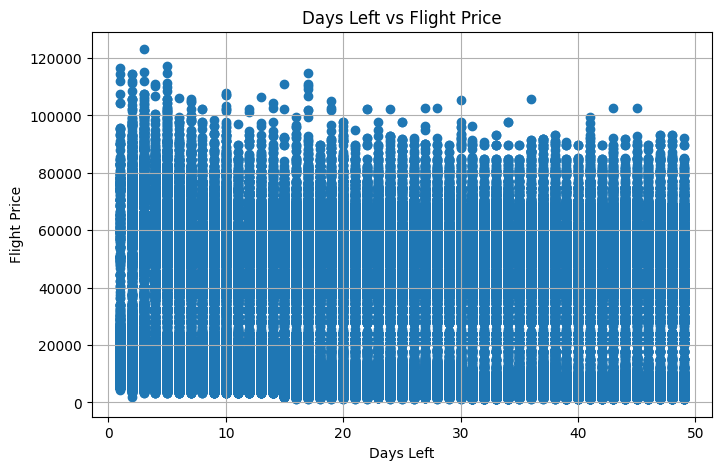

In [12]:
#Graph 1 — Days Left vs Flight Price

plt.figure(figsize=(8, 5))

plt.scatter(df['days_left'], df['price'])

plt.xlabel('Days Left')
plt.ylabel('Flight Price')
plt.title('Days Left vs Flight Price')
plt.grid(True)

plt.show()

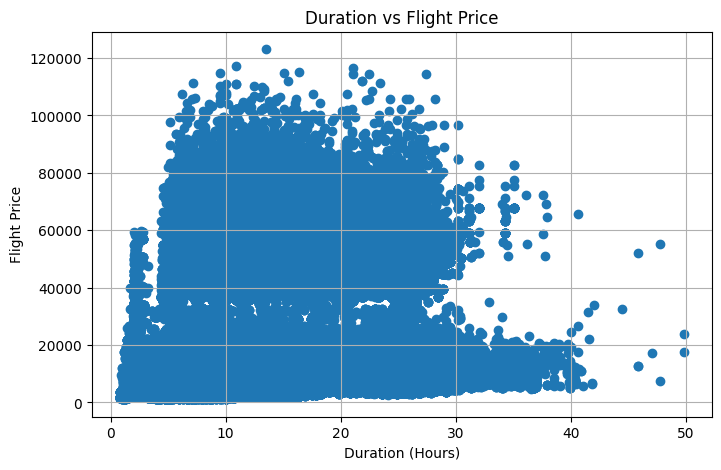

In [13]:
#Graph 2 — Duration vs Flight Price
plt.figure(figsize=(8, 5))

plt.scatter(df['duration'], df['price'])

plt.xlabel('Duration (Hours)')
plt.ylabel('Flight Price')
plt.title('Duration vs Flight Price')
plt.grid(True)

plt.show()

# **Preparing Data for Machine Learning**
**Seperate feature and target**

In [14]:
X = df[['class', 'duration', 'days_left', 'stops']]
y = df['price']

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
   class  duration  days_left  stops
0      0      2.17          1      0
1      0      2.33          1      0
2      0      2.17          1      0
3      0      2.25          1      0
4      0      2.33          1      0

Target Values:
0    5953
1    5953
2    5956
3    5955
4    5955
Name: price, dtype: int64


In [15]:
#Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training samples:",len(X_train))
print("Testing samples:",len(X_test))

Training samples: 240122
Testing samples: 60031


In [16]:
#Create the model
model=LinearRegression()

In [17]:
#Train the model
model.fit(X_train,y_train)

LinearRegression()

In [18]:
#Inspect learned parameters
print("Coefficients:")
print(model.coef_)

print("\nIntercept:")
print(model.intercept_)

Coefficients:
[45770.86463794    66.66291211  -130.07266554  6184.49803175]

Intercept:
3489.953090707011


In [19]:
#Predict the test data
y_pred=model.predict(X_test)

print("Actual Flight Price:")
print(y_test.values)

print("\nPredicted Flight Price:")
print(y_pred)

Actual Flight Price:
[ 7366 64831  6195 ...  6734  5082 66465]

Predicted Flight Price:
[ 5788.13701482 50637.56023357  5041.43241229 ...  6937.69883365
 -1579.62770683 56749.66898952]


In [20]:
#Compare Actual and predicted values
comparison=pd.DataFrame({
    "Actual Flight Price ":y_test.values,
    "Predicted Flight Price ":y_pred
    })
print(comparison)

       Actual Flight Price   Predicted Flight Price 
0                      7366              5788.137015
1                     64831             50637.560234
2                      6195              5041.432412
3                     60160             54590.910668
4                      6578              7622.966836
...                     ...                      ...
60026                  5026              7001.108587
60027                  3001              -137.495691
60028                  6734              6937.698834
60029                  5082             -1579.627707
60030                 66465             56749.668990

[60031 rows x 2 columns]


In [29]:
#Mean Absolute Error
mae=mean_absolute_error(y_test,y_pred)
print("Mean Absolute Error:",mae)

Mean Absolute Error: 4595.674349880799


In [30]:
#Mean Squared Error
mse=mean_squared_error(y_test,y_pred)
print("Mean Squared Error:",mse)

Mean Squared Error: 51471534.03497546


In [31]:
#Root Mean Squared Error
rmse=np.sqrt(mse)
print("Root Mean Squared Error:",rmse)

Root Mean Squared Error: 7174.3664553028975


In [32]:
#R2 Score
r2=r2_score(y_test,y_pred)
print("R2 Score:",r2)

R2 Score: 0.9001487797463545


In [33]:
#Predict Flight Price (Economy Class)
flight_class = 0  # 0 for Economy, 1 for Business
duration = 2.5    # in hours
days_left = 20    # days left before departure
stops = 0         # 0 for zero, 1 for one, 2 for two_or_more

new_data = pd.DataFrame({
    'class': [flight_class],
    'duration': [duration],
    'days_left': [days_left],
    'stops': [stops]
})

predicted_price = model.predict(new_data)

print("Class (0=Economy, 1=Business):", flight_class)
print("Duration (Hours):", duration)
print("Days Left:", days_left)
print("Stops:", stops)
print("Predicted Flight Price: ₹", round(predicted_price[0], 2))

Class (0=Economy, 1=Business): 0
Duration (Hours): 2.5
Days Left: 20
Stops: 0
Predicted Flight Price: ₹ 1055.16


In [26]:
#Predict Business Class Flight Price
flight_class = 1  # 1 for Business Class
duration = 2.5
days_left = 20
stops = 0

new_data_business = pd.DataFrame({
    'class': [flight_class],
    'duration': [duration],
    'days_left': [days_left],
    'stops': [stops]
})

predicted_business_price = model.predict(new_data_business)

print("Class (0=Economy, 1=Business):", flight_class)
print("Duration (Hours):", duration)
print("Days Left:", days_left)
print("Stops:", stops)
print("Predicted Flight Price: ₹", round(predicted_business_price[0], 2))

Class (0=Economy, 1=Business): 1
Duration (Hours): 2.5
Days Left: 20
Stops: 0
Predicted Flight Price: ₹ 46826.02


In [27]:
import joblib
import sklearn
#Save the trained model
joblib.dump(model, "flight_price_prediction_model.pkl")

#Check the installed scikit-learn version
print("Scikit-learn version:",sklearn.__version__)

print("Model saved successfully")

Scikit-learn version: 1.6.1
Model saved successfully


In [28]:
from google.colab import files
files.download("flight_price_prediction_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>